# Topology optimization of a layer: a band-stop line

**Question.** A parallel-plate line carries a TEM wave between two lumped ports.
Its middle 20 mm is a dielectric layer we may pattern freely with a ceramic
(ε_r = 10) or leave as air. Which pattern, fabricable with a minimum feature size of
about 1.5 mm and tolerant to over- and under-etching, passes 5 GHz and blocks 8 GHz?

We let gradients find it. The design is a planar pixel image of the layer, so the
pattern is constant through the layer's thickness, as a lithographic process makes it.
The chain from pixels to the objective is differentiable end to end:

pixels ρ → **Helmholtz filter** (length scale) → **projection** (towards ceramic / air)
→ **layer grid** to the mesh elements → **material field** ε_r → `gfem.solve` → S21.

The optimizer is not part of gfem: here it is [optax](https://optax.readthedocs.io)'s Adam.

**Assumptions.**

- Perfect conductors (PEC plates); the side walls are left unassigned, so they are
  magnetic walls (PMC) and the empty line carries an exact TEM wave.
- Lossless media; the ports are resistors matched to the empty line.
- The mesh (0.5 mm × 1 mm cells, second-order Nédélec elements) resolves the guided
  wavelength (≥ 12 mm in ceramic at 8 GHz) well enough for a design study; check a
  final design on a finer mesh.

**Conventions.** SI units at the API (the mesh file is in mm), time dependence
e^{+iωt}, S-parameters as power waves normalized to the port resistance, so |S21|² is
the fraction of the incident power delivered to port 2. See `gfem.conventions`.

In [1]:
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
from scipy.constants import epsilon_0, mu_0

import gfem
from gfem import design

GHz, mm = 1e9, 1e-3

## The line

The mesh is a 40 mm × 6 mm × 1 mm box: volume `"design"` between x = 10 mm and
30 mm, `"feed"` on both sides, plates `"bottom"` / `"top"`, port faces `"port1"`
(x = 0) and `"port2"` (x = 40 mm). It was written by `tools/make_tutorial_meshes.py`.
The empty line's characteristic impedance is η₀ h / w, and both ports are matched to it.

In [2]:
mesh = gfem.Mesh.from_gmsh(Path("data/line.msh"), length_unit="mm")
height, width = 1 * mm, 6 * mm
z_line = np.sqrt(mu_0 / epsilon_0) * height / width  # ohm, TEM line in air

AIR = gfem.Material(name="air")
CERAMIC = gfem.Material(eps_r=10.0, name="ceramic")

line = gfem.Model(
    mesh,
    materials={"feed": AIR, "design": AIR},
    boundaries=[gfem.PEC("bottom"), gfem.PEC("top")],
    ports=[
        gfem.LumpedPort("p1", "port1", "+z", impedance=z_line),
        gfem.LumpedPort("p2", "port2", "+z", impedance=z_line),
    ],
)
print(f"Z_line = {z_line:.2f} ohm")
line

Z_line = 62.79 ohm


Model(Mesh(1134 nodes, 2880 tetrahedra, volumes=['feed', 'design'], surfaces=['port1', 'side', 'bottom', 'top', 'port2'], length_unit='mm')
  materials:
    feed: Material(name='air')
    design: Material(name='air')
  boundaries:
    PEC(surface='bottom')
    PEC(surface='top')
  ports:
    LumpedPort(name='p1', surface='port1', direction=(0.0, 0.0, 1.0), resistance=None, inductance=None, capacitance=None, impedance=62.78838556863419)
    LumpedPort(name='p2', surface='port2', direction=(0.0, 0.0, 1.0), resistance=None, inductance=None, capacitance=None, impedance=62.78838556863419)
  default PMC (electromagnetic problems): side)

## From pixels to a material

`LayerGrid` lays square pixels of side `pitch` over the design volume's footprint;
each element of the volume takes the bilinear interpolation of the pixel values at
its centroid. Pixels no element samples would get no gradient, and the grid warns
about them.

The Helmholtz filter smooths the pixel image over `radius` (it solves
-r² ∇²ρ̃ + ρ̃ = ρ with r = radius / 2√3): features much smaller than the radius
cannot appear. `robust` then projects the filtered image at three thresholds:
the **eroded** (over-etched), **nominal** and **dilated** (under-etched) designs.
Optimizing the worst of the three makes the design tolerate the etch, and
guarantees the length scale on both the ceramic and the air.

In [3]:
grid = design.LayerGrid(mesh, "design", pitch=0.5 * mm)
blur = design.helmholtz_filter(grid, radius=1.5 * mm)
grid

LayerGrid('design', pitch=0.0005 m, shape=(12, 40), 1440 elements)

## The objective

For one design density (per element) we solve at the pass and the stop frequency
and read S21. The loss is the power that misses its target:
1 - |S21(5 GHz)|² + |S21(8 GHz)|², zero for an ideal band-stop.

`jax.vmap` runs the three robust designs through `gfem.solve` (one after the other
on the host); the worst one is the objective. A direct solver suits these small,
repeated solves.

In [4]:
PASS, STOP = 5 * GHz, 8 * GHz
problem = gfem.Driven(frequency=(PASS, STOP), excite="p1")
options = gfem.SolverOptions(linear_solver="direct")


def material(density):
    """The design volume's permittivity field: 0 air, 1 ceramic, per pixel."""
    return gfem.MaterialField.interpolate(grid.to_elements(density), AIR, CERAMIC)


def s21_of_field(eps):
    result = gfem.solve(line.with_material("design", eps), problem, options=options)
    return result.s["p2", "p1"]  # (2,): at PASS, STOP


def s21(density):
    return s21_of_field(material(density))


def missed_power(t):
    """The power that misses the band-stop target, from S21 at (PASS, STOP)."""
    return 1 - jnp.abs(t[..., 0]) ** 2 + jnp.abs(t[..., 1]) ** 2


DELTA = 0.15  # the etch: thresholds 0.5 - DELTA (dilated), 0.5 + DELTA (eroded)


def loss(rho, beta):
    designs = jnp.stack(design.robust(blur(rho), beta=beta, delta=DELTA))
    t = jax.vmap(s21)(designs)  # (3, 2): eroded, nominal, dilated
    missed = missed_power(t)
    return jnp.max(missed), missed


value_and_grad = jax.jit(jax.value_and_grad(loss, has_aux=True))

## Optimize

Adam on the raw pixels, clipped to [0, 1], starting from a grey layer with a little
noise to break the symmetry. The projection sharpness β is doubled every 12 steps
(continuation): a soft projection first lets material move, a sharp one at the end
makes the design binary. A few minutes on a laptop.

In [5]:
rho0 = 0.5 + 0.01 * jax.random.normal(jax.random.key(0), grid.shape)
BETAS, STEPS_PER_BETA = (2.0, 4.0, 8.0, 16.0), 12
rho = rho0
optimizer = optax.adam(0.05)
state = optimizer.init(rho)
history = []
for beta in BETAS:
    for _ in range(STEPS_PER_BETA):
        (worst, missed), g = value_and_grad(rho, beta)
        updates, state = optimizer.update(g, state)
        rho = jnp.clip(optax.apply_updates(rho, updates), 0.0, 1.0)
        history.append(np.asarray(missed))
    print(
        f"beta = {beta:4.0f}: missed power (eroded, nominal, dilated) = "
        f"{np.array2string(np.asarray(missed), precision=4)}"
    )

beta =    2: missed power (eroded, nominal, dilated) = [0.0453 0.0462 0.0693]


beta =    4: missed power (eroded, nominal, dilated) = [0.0262 0.0253 0.0487]


beta =    8: missed power (eroded, nominal, dilated) = [0.0266 0.0184 0.0198]


beta =   16: missed power (eroded, nominal, dilated) = [0.0203 0.0175 0.017 ]


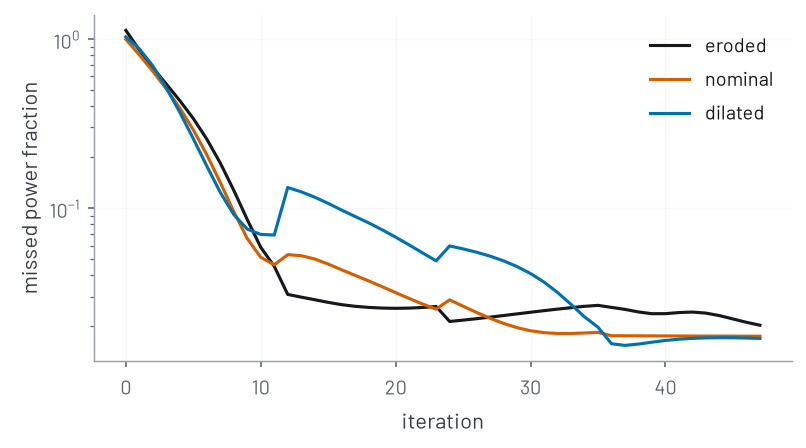

In [6]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.semilogy(np.array(history), label=["eroded", "nominal", "dilated"])
ax.set_xlabel("iteration")
ax.set_ylabel("missed power fraction")
ax.legend()
ax.grid(alpha=0.3);

## The design

The final pixels, filtered and projected at a sharp β, give the three fabricated
variants. White is ceramic, black is air; the wave travels along x.

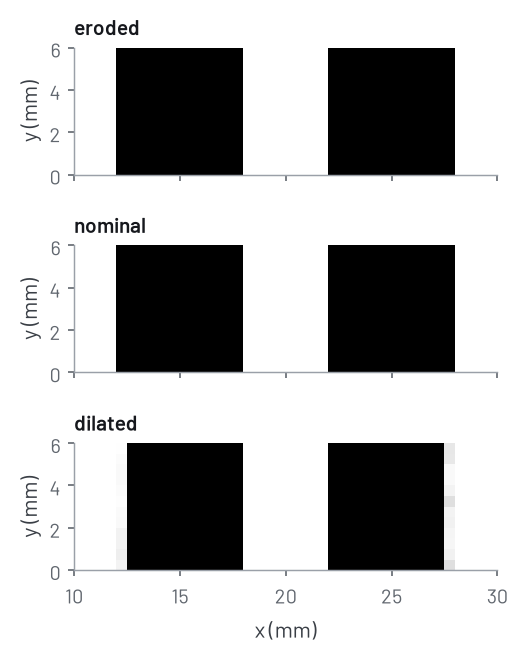

In [7]:
final = design.robust(blur(rho), beta=64.0, delta=DELTA)
extent = (
    np.array(
        [
            grid.origin[0],
            grid.origin[0] + grid.shape[1] * grid.pitch,
            grid.origin[1],
            grid.origin[1] + grid.shape[0] * grid.pitch,
        ]
    )
    / mm
)
fig, axes = plt.subplots(3, 1, figsize=(7, 4.5), sharex=True)
for ax, name, image in zip(axes, final._fields, final, strict=True):
    ax.imshow(image, origin="lower", extent=extent, cmap="gray", vmin=0, vmax=1)
    ax.set_title(name, fontsize=10)
    ax.set_ylabel("y (mm)")
axes[-1].set_xlabel("x (mm)")
fig.tight_layout()

## Trust: the transmission spectrum

A sweep of the nominal design (and of its eroded and dilated variants) shows the stop
band around 8 GHz while 5 GHz passes. The check here is physical: the line is lossless
and both ports are matched, so |S11|² + |S21|² = 1 at every frequency.

max | |S11|^2 + |S21|^2 - 1 | (nominal) = 7.5e-10


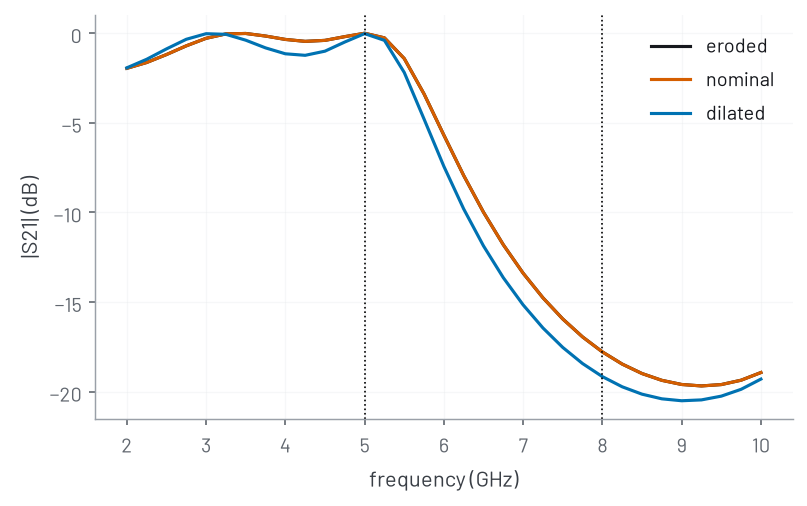

In [8]:
sweep = gfem.Driven(frequency=np.linspace(2, 10, 33) * GHz, excite="p1")
fig, ax = plt.subplots(figsize=(6, 3.5))
for name, image in zip(final._fields, final, strict=True):
    eps = gfem.MaterialField.interpolate(grid.to_elements(image), AIR, CERAMIC)
    s = gfem.solve(line.with_material("design", eps), sweep, options=options).s
    s11, s21_ = np.asarray(s["p1", "p1"]), np.asarray(s["p2", "p1"])
    ax.plot(np.asarray(sweep.frequency) / GHz, 20 * np.log10(np.abs(s21_)), label=name)
    if name == "nominal":
        balance = np.max(np.abs(np.abs(s11) ** 2 + np.abs(s21_) ** 2 - 1))
for f in (PASS, STOP):
    ax.axvline(f / GHz, color="k", lw=0.8, ls=":")
ax.set_xlabel("frequency (GHz)")
ax.set_ylabel("|S21| (dB)")
ax.legend()
ax.grid(alpha=0.3)
print(f"max | |S11|^2 + |S21|^2 - 1 | (nominal) = {balance:.1e}")

## Variant: a patterned resistive sheet

The same chain designs metal instead of dielectric: a `gfem.SheetField` holds one
fill per face of an interior surface and scales the admittance of the `Conductor`
or `Impedance` on it (0 = no film, 1 = the solid film). Here the line's plates are
its side walls (y = 0 and 6 mm), so the TEM field lies in the horizontal sheet that
the mesh carries at mid-height over the design length, and a resistive film there
absorbs. The goal is a **matched 3 dB attenuator** at 6 GHz: |S21|² = 1/2 with no
reflection, out of a 300 Ω/sq film that may only be present or absent.

The chain is the layer design's with two changes: `LayerGrid` on the surface maps
pixels to faces (`to_faces`), and `SheetField.interpolate` maps the density to the
fill exponentially (log-scale in the admittance, exact 0 and 1). Its `contrast`
sets where in the density range the film starts to matter; a weak solid (η₀|Y| of
about 1 here) takes a low one. See `docs/recipes/sheet-design.md`.

In [9]:
sheet_mesh = gfem.Mesh.from_gmsh(Path("data/sheet_line.msh"), length_unit="mm")
z_sheet_line = np.sqrt(mu_0 / epsilon_0) * 6 / 2  # plates 6 mm apart, 2 mm high
FILM = 300.0  # ohm per square: the solid film

sheet_line = gfem.Model(
    sheet_mesh,
    materials={"lower": AIR, "upper": AIR},
    boundaries=[gfem.PEC("plate1"), gfem.PEC("plate2")],
    ports=[
        gfem.LumpedPort("p1", "port1", "+y", impedance=z_sheet_line),
        gfem.LumpedPort("p2", "port2", "+y", impedance=z_sheet_line),
    ],
)
sheet_grid = design.LayerGrid(sheet_mesh, "sheet", pitch=1 * mm)
sheet_blur = design.helmholtz_filter(sheet_grid, radius=3 * mm)
attenuation = gfem.Driven(frequency=6 * GHz, excite="p1")


def sheet_s(density):
    fill = gfem.SheetField.interpolate(sheet_grid.to_faces(density), contrast=1e3)
    film = gfem.Impedance("sheet", resistance=FILM, fill=fill)
    model = sheet_line.replace(boundaries=[*sheet_line.boundaries, film])
    s = gfem.solve(model, attenuation, options=options).s
    return s["p1", "p1"][0], s["p2", "p1"][0]


def sheet_loss(rho, beta):
    s11, s21 = sheet_s(design.project(sheet_blur(rho), beta=beta))
    return (jnp.abs(s21) ** 2 - 0.5) ** 2 + jnp.abs(s11) ** 2


sheet_value_and_grad = jax.jit(jax.value_and_grad(sheet_loss))
sheet_grid

LayerGrid('sheet', pitch=0.001 m, shape=(6, 20), 240 faces)

In [10]:
rho = 0.5 + 0.01 * jax.random.normal(jax.random.key(1), sheet_grid.shape)
state = optimizer.init(rho)
for beta in (2.0, 4.0, 8.0):
    for _ in range(8):
        value, g = sheet_value_and_grad(rho, beta)
        updates, state = optimizer.update(g, state)
        rho = jnp.clip(optax.apply_updates(rho, updates), 0.0, 1.0)
    print(f"beta = {beta:3.0f}: loss = {float(value):.2e}")

beta =   2: loss = 3.90e-03


beta =   4: loss = 1.35e-03


beta =   8: loss = 1.87e-02


The film pattern (white is film) and the power balance of the result at the last
β. The line is otherwise lossless, so 1 - |S11|² - |S21|² is the power the film
absorbs.

|S11|^2 = 0.000, |S21|^2 = 0.454, absorbed = 0.546


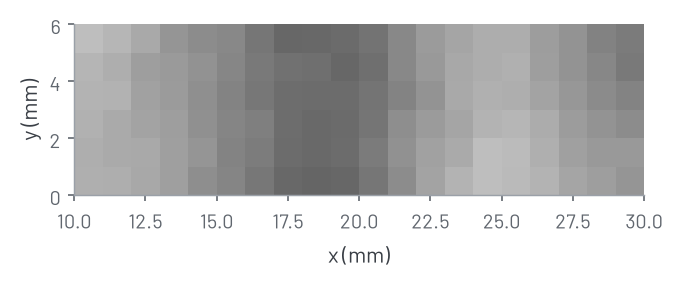

In [11]:
density = design.project(sheet_blur(rho), beta=8.0)
r11, t21 = (complex(v) for v in sheet_s(density))
print(
    f"|S11|^2 = {abs(r11) ** 2:.3f}, |S21|^2 = {abs(t21) ** 2:.3f}, "
    f"absorbed = {1 - abs(r11) ** 2 - abs(t21) ** 2:.3f}"
)
extent = (
    np.array(
        [
            sheet_grid.origin[0],
            sheet_grid.origin[0] + sheet_grid.shape[1] * sheet_grid.pitch,
            sheet_grid.origin[1],
            sheet_grid.origin[1] + sheet_grid.shape[0] * sheet_grid.pitch,
        ]
    )
    / mm
)
fig, ax = plt.subplots(figsize=(7, 2))
ax.imshow(density, origin="lower", extent=extent, cmap="gray", vmin=0, vmax=1)
ax.set_xlabel("x (mm)")
ax.set_ylabel("y (mm)")
fig.tight_layout()

## Limits

- The design is only as good as the mesh: the optimizer exploits discretization
  error. Re-check the final design on a refined mesh (and with `order=3`).
- `radius` sets a length scale through the filter and the robust thresholds, not a
  hard design rule; foundry rules (minimum width, spacing) need explicit constraints.
- `jax.vmap` over `gfem.solve` runs the three designs one after the other. Every
  iteration costs three solves per frequency.
- Recipes on the pixel array: pin regions with `jnp.where(mask, 1.0, rho)` before the
  filter (feed connections), impose a mirror symmetry with
  `(rho + rho[:, ::-1]) / 2`, and mask pixels outside a non-rectangular footprint
  with `grid.sampled`.

## Next

- `docs/recipes/s-parameter-gradient.md`: what is differentiable in a driven solve.
- `docs/recipes/sheet-design.md`: sheet designs (interpolation, solvers, what raises).
- `gfem.design` reference: `LayerGrid`, `helmholtz_filter`, `project`, `robust`.